# 現在のoff：評価ニューロン数と素材分類の正答率

`p_E_readout-0.11__g_e_out-0.2706/off/`の保存済み結果を使い、STDP・230 msと同じ条件でニューロン削減を評価します。

- rep1〜5、各rep10通りのランダム削減順、80→75→…→5ニューロン。
- 同じ削減順では選択集合を入れ子にし、全素材・全CV foldで同じニューロンを使います。
- 25 msビン、10分割層別交差検証、クラス別正則化マハラノビス分類。PCA・標準化なし。
- 全80個の正答率は各repで1回計算し、現在の分類Excelとの一致を確認します。
- 保存された応答を選択する解析です。ネットワーク・重みは変更せず、学習や発火シミュレーションは行いません。
- 集計・図はノートブック内だけに表示し、別の結果ファイルは保存しません。


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager
from sklearn.model_selection import StratifiedKFold
from threadpoolctl import threadpool_limits
from concurrent.futures import ThreadPoolExecutor, as_completed
from tqdm.auto import tqdm

# h_analysis・LSM・その親から起動しても同じプロジェクトを参照する。
working_dir = Path.cwd().resolve()
PROJECT_ROOT = next((candidate for parent in (working_dir, *working_dir.parents)
                     for candidate in (parent, parent / "LSM")
                     if (candidate / "d_tools/classification.py").is_file()), None)
if PROJECT_ROOT is None:
    raise FileNotFoundError("LSMプロジェクトが見つかりません。")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from d_tools.classification import classify
from d_tools.evaluation import extract_features, evaluate_classification
from d_tools.evaluation_excel import load_classification_results
from d_tools.recording_io import read_record

# STDP・230 msの削減評価と、rep・削減順の乱数・集約時間を揃える。
OFF_ROOT = PROJECT_ROOT / "g_tactile_results/readout_run/p_E_readout-0.11__g_e_out-0.2706/off"
REPS = list(range(1, 6))
NEURON_COUNTS = list(range(80, 0, -5))
N_SELECTIONS = 10
SELECTION_SEED = 20261031
BIN_MS = 25
N_FOLDS = 10
EVALUATION_SEED = 1
REGULARIZATION = 1e-6
REP_WORKERS = 3  # 同時に評価するrep数。各rep内の数値演算は1スレッド。

available_fonts = {font.name for font in font_manager.fontManager.ttflist}
for font_name in ("Yu Gothic", "Meiryo", "Noto Sans CJK JP", "MS Gothic"):
    if font_name in available_fonts:
        plt.rcParams["font.family"] = font_name
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 110

# 古い結果を混ぜず、試行初期化設定と必要な入力が揃っていることを確認する。
MATERIALS = None
for rep in REPS:
    test_dir = OFF_ROOT / f"rep{rep}/test"
    for relative_path in (f"rec/readout/sout_rec_rep{rep}.npy", "test_config_snapshot.json", f"test_trial_ids_rep{rep}.npy", "eval/classification.xlsx"):
        if not (test_dir / relative_path).is_file():
            raise FileNotFoundError(test_dir / relative_path)
    metadata = read_record(test_dir / "test_config_snapshot.json")
    if any(metadata["common"].get(key) != "reset_each_trial" for key in ("LIQUID_STATE_POLICY", "READOUT_STATE_POLICY")):
        raise ValueError(f"試行間初期化のoff結果ではありません：{test_dir}")
    if MATERIALS is None:
        MATERIALS = list(metadata["materials"])
    elif MATERIALS != metadata["materials"]:
        raise ValueError(f"rep間で素材順が異なります：{test_dir}")
print(f"読み込み先：{OFF_ROOT}")
print(f"rep={REPS}、ニューロン数={NEURON_COUNTS}、各repの削減順={N_SELECTIONS}通り")


読み込み先：C:\Users\haru4\研究\研究コード\LSM\g_tactile_results\readout_run\p_E_readout-0.11__g_e_out-0.2706\off
rep=[1, 2, 3, 4, 5]、ニューロン数=[80, 75, 70, 65, 60, 55, 50, 45, 40, 35, 30, 25, 20, 15, 10, 5]、各repの削減順=10通り


In [2]:
def evaluate_off_repetition(rep):
    """1つのrepを固定したCV分割と10通りの入れ子の削減順で評価する。"""
    test_dir = OFF_ROOT / f"rep{rep}/test"
    metadata = read_record(test_dir / "test_config_snapshot.json")
    saved_evaluation = load_classification_results(test_dir / "eval/classification.xlsx")
    if saved_evaluation is None or saved_evaluation["materials"] != MATERIALS:
        raise ValueError(f"分類Excelの素材情報を読めません：{test_dir}")
    if saved_evaluation["T_n_ms"] != [BIN_MS] or int(saved_evaluation["folds"]) != N_FOLDS or int(saved_evaluation["base_seed"]) != EVALUATION_SEED:
        raise ValueError(f"保存済み分類と評価条件が一致しません：{test_dir}")
    saved_rows = [row for row in saved_evaluation["summary"] if int(row["rep"]) == rep and float(row["T_n_ms"]) == BIN_MS]
    if len(saved_rows) != 1:
        raise ValueError(f"全80個の比較対象を一意に選べません：{test_dir}")
    counts = np.load(test_dir / f"rec/readout/sout_rec_rep{rep}.npy", mmap_mode="r", allow_pickle=False)
    trial_ids = np.load(test_dir / f"test_trial_ids_rep{rep}.npy", allow_pickle=False)
    if counts.ndim != 4 or counts.shape[0] != len(MATERIALS) or counts.shape[1] != len(trial_ids) or counts.shape[2] != 80:
        raise ValueError(f"発火記録の形が不正です：{test_dir}")
    if int(np.asarray(trial_ids).size) != len(np.unique(trial_ids)):
        raise ValueError(f"試行IDが重複しています：{test_dir}")
    n_materials, n_trials = counts.shape[:2]
    features = extract_features(counts, BIN_MS, bin_width_ms=metadata["recording_bin_width_ms"])
    time_bins = features.shape[-1] // 80
    states_hz = features.reshape(n_materials * n_trials, 80, time_bins)
    del counts
    labels = np.repeat(np.arange(n_materials), n_trials)
    splitter = StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=EVALUATION_SEED + rep - 1)
    splits = list(splitter.split(np.zeros(len(labels)), labels))
    rows, order_records = [], []
    baseline_accuracy = None
    for selection in range(1, N_SELECTIONS + 1):
        # STDP側と同じrep・選択番号なら、同じニューロンIDの削減順になる。
        rng = np.random.default_rng(np.random.SeedSequence([SELECTION_SEED, rep, selection]))
        order = rng.permutation(80)
        order_records.append({"rep": rep, "selection": selection, "neuron_order": order.tolist()})
        for retained in NEURON_COUNTS:
            if retained == 80 and baseline_accuracy is not None:
                accuracy = baseline_accuracy
            else:
                neuron_ids = np.sort(order[:retained])
                selected = states_hz[:, neuron_ids, :].reshape(len(labels), -1)
                predictions = np.empty_like(labels)
                for train, test in splits:
                    active = np.any(selected[train] != 0, axis=0)
                    if not active.any():
                        raise ValueError(f"学習側に発火する特徴がありません：rep{rep}, {retained} neurons")
                    predictions[test] = classify(selected[train][:, active], labels[train], selected[test][:, active], regularization=REGULARIZATION)
                metrics = evaluate_classification(labels, predictions, labels=np.arange(n_materials))
                accuracy = 100 * metrics["accuracy"]
                if retained == 80:
                    baseline_accuracy = accuracy
                    if not np.isclose(accuracy, 100 * float(saved_rows[0]["accuracy"])):
                        raise ValueError(f"全80個の再評価が現在の分類Excelと一致しません：rep{rep}")
            rows.append({"rep": rep, "selection": selection, "n_neurons": retained, "accuracy_pct": accuracy})
    return rows, order_records

# rep間は独立なので並列評価する。分類結果や乱数は完了順に依存しない。
selection_rows = []
removal_order_records = []
with threadpool_limits(limits=1):
    with ThreadPoolExecutor(max_workers=min(REP_WORKERS, len(REPS))) as pool:
        futures = {pool.submit(evaluate_off_repetition, rep): rep for rep in REPS}
        for future in tqdm(as_completed(futures), total=len(futures), desc="off neuron reduction", unit="rep"):
            rows, orders = future.result()
            selection_rows.extend(rows)
            removal_order_records.extend(orders)
selection_results = pd.DataFrame(selection_rows).sort_values(["rep", "selection", "n_neurons"], ascending=[True, True, False]).reset_index(drop=True)
rep_means = selection_results.groupby(["n_neurons", "rep"], as_index=False)["accuracy_pct"].mean()
summary = (rep_means.groupby("n_neurons")["accuracy_pct"]
           .agg(mean_pct="mean", sd_pct="std", min_rep_pct="min", max_rep_pct="max", n_reps="count")
           .reindex(NEURON_COUNTS))
print("現在のoff：各rep内で10通りを平均し、rep間の平均とSDを計算")
print(summary.round(3).to_string())
print("\n全80個のrep別正答率（分類Excelとの一致を確認済み）")
print(rep_means[rep_means["n_neurons"] == 80].round(3).to_string(index=False))


現在のoff：各rep内で10通りを平均し、rep間の平均とSDを計算
           mean_pct  sd_pct  min_rep_pct  max_rep_pct  n_reps
n_neurons                                                    
80           92.625   0.375       92.250       93.250       5
75           92.668   0.213       92.462       92.975       5
70           92.570   0.177       92.350       92.812       5
65           92.443   0.118       92.338       92.575       5
60           92.480   0.148       92.350       92.712       5
55           92.263   0.236       92.100       92.675       5
50           91.895   0.289       91.488       92.225       5
45           91.602   0.348       91.212       92.000       5
40           91.100   0.321       90.850       91.625       5
35           90.670   0.327       90.350       91.212       5
30           89.890   0.355       89.475       90.375       5
25           88.617   0.416       88.188       89.038       5
20           86.662   0.708       86.012       87.862       5
15           83.845   0.742       

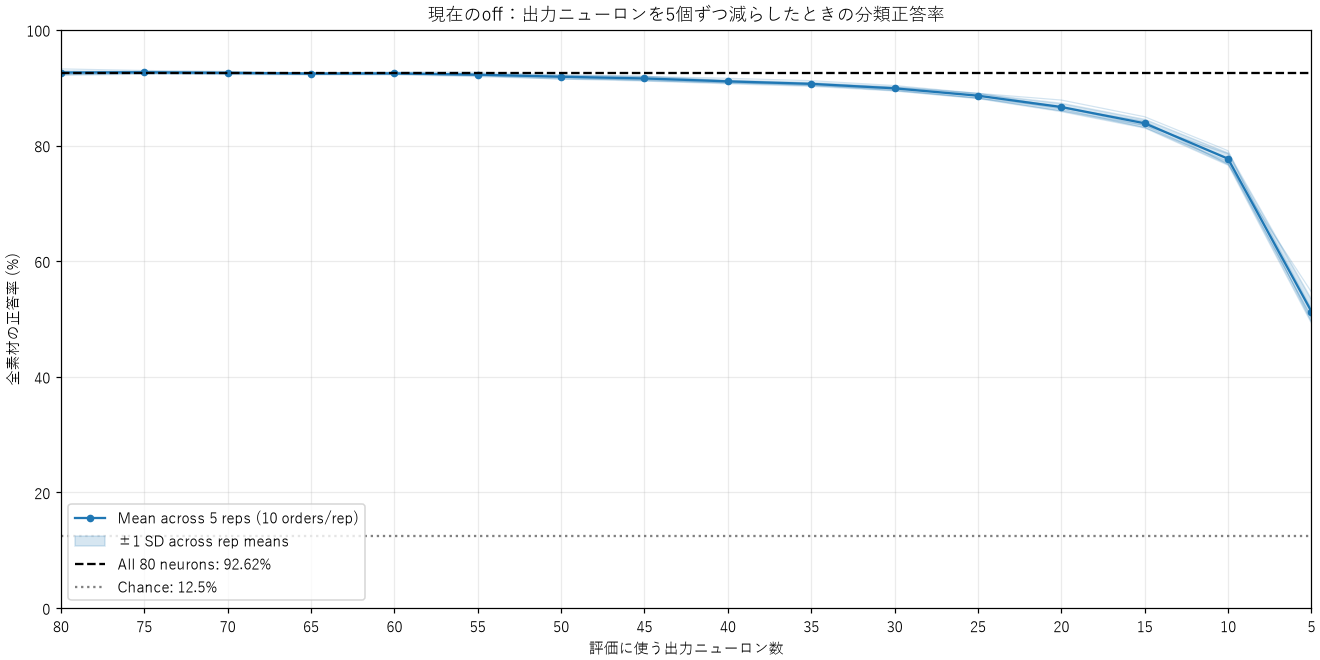

In [3]:
# 80個から5個へ減らしたときの曲線。薄い線は各repの選択平均。
fig, ax = plt.subplots(figsize=(12, 6), layout="constrained")
for rep in REPS:
    selected = rep_means[rep_means["rep"] == rep].set_index("n_neurons").reindex(NEURON_COUNTS)
    ax.plot(selected.index, selected["accuracy_pct"], color="tab:blue", alpha=0.2, linewidth=0.8)
x = summary.index.to_numpy()
y = summary["mean_pct"].to_numpy()
sd = summary["sd_pct"].to_numpy()
ax.plot(x, y, "o-", color="tab:blue", markersize=4, label=f"Mean across {len(REPS)} reps (10 orders/rep)")
ax.fill_between(x, y-sd, y+sd, color="tab:blue", alpha=0.18, label="±1 SD across rep means")
ax.axhline(summary.loc[80, "mean_pct"], color="black", linestyle="--", label=f"All 80 neurons: {summary.loc[80, 'mean_pct']:.2f}%")
ax.axhline(100 / len(MATERIALS), color="gray", linestyle=":", label=f"Chance: {100 / len(MATERIALS):.1f}%")
ax.set(xlim=(80, 5), ylim=(0, 100), xticks=NEURON_COUNTS, xlabel="評価に使う出力ニューロン数", ylabel="全素材の正答率 (%)", title="現在のoff：出力ニューロンを5個ずつ減らしたときの分類正答率")
ax.grid(alpha=0.25)
ax.legend(loc="lower left")
plt.show()


## 結果の読み方

- 10通りのランダム選択を各repで平均し、線はその5rep平均、帯はrep間の標本標準偏差（±1 SD）です。fold間SDや50通り全体のSDとは異なります。
- STDP側と同じ選択seed・rep・選択番号を使うため、同じニューロンIDの削減順で比較できます。
- 正答率が高く保たれても、選ばれなかったニューロンが学習やネットワークの動作に不要とは断定できません。ここでは保存済み応答の読み取りだけを減らしています。
- 既定の対象はrep1〜5です。追加repも含める場合は`REPS`を変更して上から実行してください。
